# Bloque 5. Exploración de la serie temporal, climatología y anomalías

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alvaroparedesl/geomatica-aplicada/blob/main/talleres/fair-series-temporales/05_exploracion_series.ipynb) [![Licencia: GPL-3.0](https://img.shields.io/badge/licencia-GPL--3.0-blue.svg)](https://github.com/alvaroparedesl/geomatica-aplicada/blob/main/LICENSE) [![Python 3.13](https://img.shields.io/badge/python-3.13-blue.svg)](https://colab.research.google.com/)

Taller *Datos FAIR, series temporales satelitales y detección de anomalías con Python*. Día 2, mañana (unos 85 minutos).

Partimos del parquet que guardaste ayer, sin recalcular nada: ese es el punto de tener la serie en un archivo con metadatos. Ahora toca **mirarla con números**: qué valores típicos tiene cada punto, cómo cambia en el tiempo, qué es estacional y qué es raro.

**Qué vas a hacer**

| Parte | Tema | Minutos |
|---|---|---|
| 1 | Cargar el parquet y sus metadatos | 10 |
| 2 | Estadísticos descriptivos por punto | 10 |
| 3 | Fechas irregulares y media móvil | 10 |
| 4 | Tendencia lineal, y qué puede decir un solo año | 15 |
| 5 | Patrones estacionales | 10 |
| 6 | Anomalías con un año de datos (z-score) | 15 |
| 7 | Preparando el bloque 7: climatología y anomalías con Landsat | 10 |
| 8 | Interpretación: pluma del Biobío, clorofila en la bahía y humedal | 5 |

## Preparar el entorno

La celda `Preparar entorno` clona el repositorio del curso (para usar `utils/`). Este bloque solo usa pandas, numpy, scipy, matplotlib y pyarrow, que Colab ya trae: no hay nada más que instalar.

In [1]:
# @title Preparar entorno (ejecutar primero)
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:  # Colab: clonar el repositorio (y actualizarlo si ya estaba)
    RAIZ = Path("/content/geomatica-aplicada")
    if not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/alvaroparedesl/geomatica-aplicada", str(RAIZ)], check=True)
    else:  # una sesión anterior ya lo clonó: traer lo nuevo para no usar código viejo
        subprocess.run(["git", "-C", str(RAIZ), "pull", "-q", "--ff-only"], check=False)
else:  # Local: subir desde la carpeta actual hasta encontrar utils/
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir())
sys.path.insert(0, str(RAIZ))
DATOS = RAIZ / "talleres" / "fair-series-temporales" / "datos"  # carpeta con los archivos de datos del taller

In [2]:
# @title Importar bibliotecas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Funciones de apoyo del curso (carpeta utils/)
from utils.extremos import controlar_calidad_agua
from utils.series import anomalias_zscore, resumen_validez, tendencia_lineal

# Una paleta que se distingue bien con daltonismo (Okabe-Ito), un color por punto
PALETA = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]
VARIABLES = ["ndwi", "ndci", "b04", "ndvi"]
ETIQUETAS = {"ndwi": "NDWI (agua)", "ndci": "NDCI (clorofila)", "b04": "B04, reflectancia roja (turbidez)", "ndvi": "NDVI (vegetación)"}

## 1. Cargar el parquet y sus metadatos

Usamos `series_sentinel2_concepcion.parquet`, la serie de 12 meses preparada con el mismo flujo del bloque 4 (si guardaste tu propio parquet de tres meses, puedes cargarlo igual con `pd.read_parquet` y la ruta de tu archivo, pero los resultados de este cuaderno hablan de los 12 meses). Primero lo que el archivo dice de sí mismo:

In [3]:
ruta = DATOS / "serie_humboldt_sentinel2.parquet"
tabla = pd.read_parquet(ruta)
# Los metadatos viajan dentro del archivo, como bytes (la clave "pandas" es de pandas y no nos interesa)
metadatos = {k.decode(): v.decode() for k, v in pq.read_schema(ruta).metadata.items() if k != b"pandas"}
print(metadatos["titulo"])
print("Fuente:", metadatos["fuente"])
print("Licencia:", metadatos["licencia"])
print(f"\n{len(tabla)} filas, {tabla['id'].nunique()} puntos, {tabla['fecha'].min():%Y-%m-%d} a {tabla['fecha'].max():%Y-%m-%d}")
tabla.head(3)

Series temporales Sentinel-2 en archipielago de Humboldt (2020-01-01 a 2026-10-01)
Fuente: ESA Copernicus Sentinel-2 L2A, leído como COG desde Microsoft Planetary Computer (colección sentinel-2-l2a)
Licencia: Datos Copernicus Sentinel de acceso libre y abierto (Reglamento UE 1159/2013). Cita: contiene datos Copernicus Sentinel modificados (2026).

5934 filas, 6 puntos, 2020-01-02 a 2026-09-29


,id,nombre,tipo,lat,lon,fecha,ndwi,ndci,b04,ndvi,nubes_escena,pixeles_validos,n_pixeles,offset_reflectancia
0,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-02 14:47:19.024,NaN,NaN,NaN,NaN,83.536118,0.0,704,0.0
1,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-04 14:37:21.024,NaN,NaN,NaN,NaN,64.026910,0.0,704,0.0
2,callejon,Callejón Isla Choros y Damas,insular,-29.242793,-71.532855,2020-01-07 14:47:21.024,0.056287,0.01301,0.0623,0.001462,3.317222,1.0,704,0.0


Recuerda que en cada punto hay fechas en las que **la ventana estaba tapada** y los índices son NaN: las fechas se conservan para que se vea el vacío. `resumen_validez` cuenta cuántas sirven. Casi todo este bloque trabaja con una serie por punto y variable. La sacamos de la tabla filtrando por punto, usando la fecha como índice y quitando los NaN: queda una `pandas.Series` con índice de fechas y **sin los NaN**.

In [4]:
resumen_validez(tabla)[["nombre", "fechas", "fechas_validas", "porcentaje_valido", "pixeles_validos_medio"]]

,nombre,fechas,fechas_validas,porcentaje_valido,pixeles_validos_medio
id,,,,,
callejon,Callejón Isla Choros y Damas,989,313,32.0,0.32
carrizalillo,Playa Carrizalillo,989,330,33.0,0.33
elapolillado,Playa El Apolillado,989,309,31.0,0.30
elapolillado02,El Apolillado 02,989,320,32.0,0.32
humedal_loschoros,Humedal Quebrada Los Choros,989,372,38.0,0.37
playa_loschoros,Playa Los Choros,989,360,36.0,0.37


In [ ]:
pluma_b04 = tabla[tabla["id"] == "callejon"].set_index("fecha")["b04"].dropna()
print(type(pluma_b04).__name__, len(pluma_b04), "valores")
pluma_b04.head(4)

Series 315 valores


,b04
fecha,
2020-01-07 14:47:21.024,0.0623
2020-01-09 14:37:19.024,0.0050
2020-01-24 14:36:51.024,0.0084
2020-01-27 14:47:01.024,0.1440


## 2. Estadísticos descriptivos por punto

Media, mediana y percentiles. Con series ambientales conviene mirar siempre más de un número, porque los valores extremos (una nube que se coló, un evento real) tiran de la media pero casi no mueven la mediana.

In [5]:
def resumen_variable(variable):
    """Estadísticos descriptivos de una variable, un punto por fila."""
    grupo = tabla.groupby("id", sort=False)[variable]
    return pd.DataFrame({
        "n": grupo.count(), "media": grupo.mean(), "mediana": grupo.median(),
        "p10": grupo.quantile(0.10), "p90": grupo.quantile(0.90), "desv": grupo.std(), "min": grupo.min(), "max": grupo.max(),
    }).round(3)


print("B04 (reflectancia roja)")
resumen_variable("ndvi")

B04 (reflectancia roja)


,n,media,mediana,p10,p90,desv,min,max
id,,,,,,,,
callejon,313,-0.094,-0.059,-0.256,0.004,0.138,-0.900,0.320
carrizalillo,330,-0.150,-0.115,-0.350,0.000,0.175,-0.867,0.818
elapolillado,309,-0.251,-0.224,-0.461,-0.063,0.162,-0.909,0.018
elapolillado02,320,-0.116,-0.092,-0.277,0.000,0.132,-0.727,0.467
humedal_loschoros,372,0.074,0.066,0.047,0.124,0.029,0.024,0.173
playa_loschoros,360,-0.172,-0.143,-0.392,0.000,0.170,-0.926,0.232


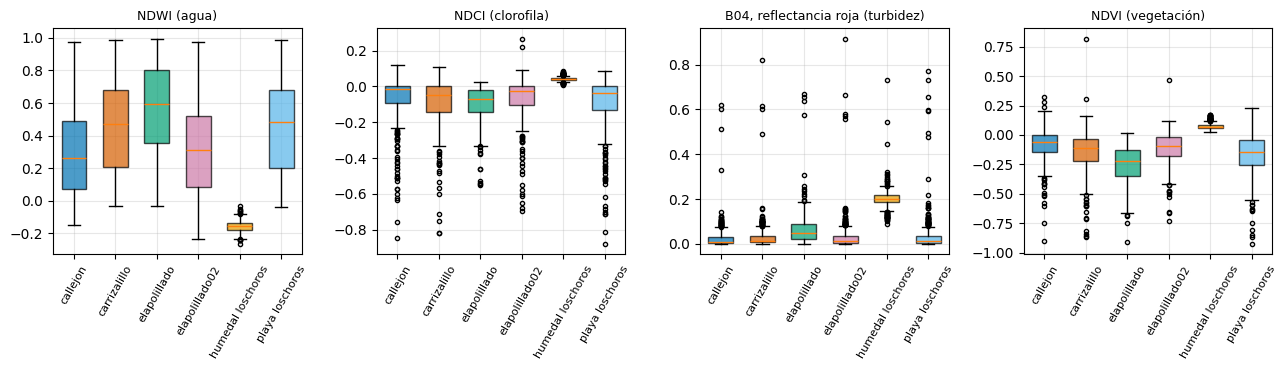

In [6]:
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.8))
orden = list(tabla["id"].unique())
for eje, variable in zip(ejes, VARIABLES):
    datos = [tabla.loc[tabla["id"] == punto, variable].dropna() for punto in orden]
    caja = eje.boxplot(datos, tick_labels=[punto.replace("_", " ") for punto in orden], patch_artist=True, widths=0.6,
                       flierprops={"markersize": 3})
    for parche, color in zip(caja["boxes"], PALETA):
        parche.set_facecolor(color)
        parche.set_alpha(0.7)
    eje.set_title(ETIQUETAS[variable], fontsize=9)
    eje.tick_params(axis="x", rotation=60, labelsize=8)
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Se crean la tablas para cada variable `resumen_variable("ndci")` y `resumen_variable("ndvi")`.

In [7]:
# Tu turno 1
resumen_variable("ndci")

,n,media,mediana,p10,p90,desv,min,max
id,,,,,,,,
callejon,310,-0.079,-0.014,-0.265,0.012,0.147,-0.846,0.117
carrizalillo,330,-0.095,-0.047,-0.268,0.010,0.140,-0.818,0.109
elapolillado,309,-0.100,-0.069,-0.249,0.000,0.107,-0.548,0.023
elapolillado02,319,-0.073,-0.027,-0.215,0.015,0.130,-0.692,0.267
humedal_loschoros,372,0.042,0.041,0.030,0.058,0.012,0.006,0.087
playa_loschoros,361,-0.097,-0.036,-0.282,0.013,0.156,-0.879,0.088


In [9]:
resumen_variable("ndvi")

,n,media,mediana,p10,p90,desv,min,max
id,,,,,,,,
callejon,313,-0.094,-0.059,-0.256,0.004,0.138,-0.900,0.320
carrizalillo,330,-0.150,-0.115,-0.350,0.000,0.175,-0.867,0.818
elapolillado,309,-0.251,-0.224,-0.461,-0.063,0.162,-0.909,0.018
elapolillado02,320,-0.116,-0.092,-0.277,0.000,0.132,-0.727,0.467
humedal_loschoros,372,0.074,0.066,0.047,0.124,0.029,0.024,0.173
playa_loschoros,360,-0.172,-0.143,-0.392,0.000,0.170,-0.926,0.232


## 3. Fechas irregulares y media móvil

Una serie de Sentinel-2 **no es diaria ni regular**. Hay más fechas útiles en verano (menos nubes) que en invierno. Mira cuántas fechas distintas hay por mes (considerando las seis ubicaciones):

In [10]:
fechas_mes = tabla.groupby(tabla["fecha"].dt.to_period("M"))["fecha"].nunique()
validas_mes = tabla.dropna(subset=["ndci"]).groupby(tabla["fecha"].dt.to_period("M")).size() / tabla["id"].nunique()
cuenta = pd.DataFrame({"fechas con imagen": fechas_mes, "observaciones válidas por punto (promedio)": validas_mes.round(1)})
cuenta

,fechas con imagen,observaciones válidas por punto (promedio)
fecha,,
2020-01,12,4.0
2020-02,12,3.8
2020-03,12,3.8
2020-04,12,5.7
2020-05,13,3.8
...,...,...
2026-05,12,3.2
2026-06,11,3.7
2026-07,14,3.0


Para cada punto de muestreo se grafica la reflectancia en la banda roja (B04) y se comparan dos maneras de suavizar la serie con una media móvil. La primera usa una ventana fija de días de calendario (60 días), así que cada promedio cubre el mismo periodo de tiempo aunque haya más o menos imágenes en él. La segunda usa un número fijo de observaciones (9), así que cada promedio incluye la misma cantidad de datos aunque estén más juntos o más separados en el tiempo. Ponerlas lado a lado muestra que, cuando las imágenes no están espaciadas de forma regular (por ejemplo, por nubes), las dos formas de suavizar pueden dar curvas diferentes. Los puntos sin datos se omiten con un aviso.

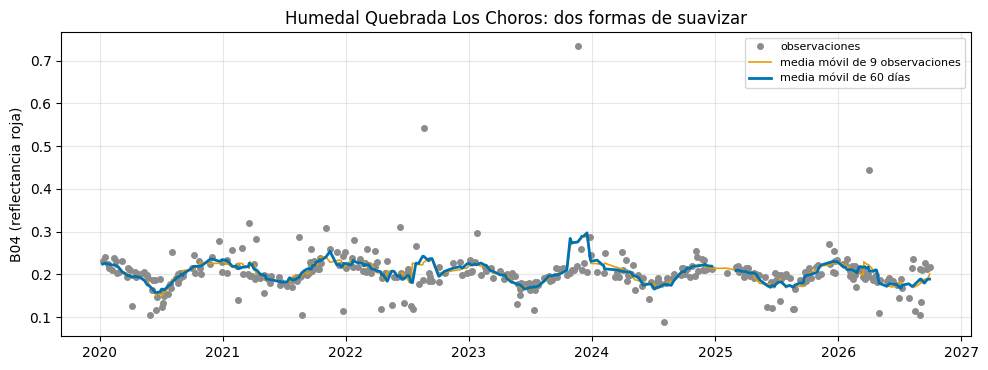

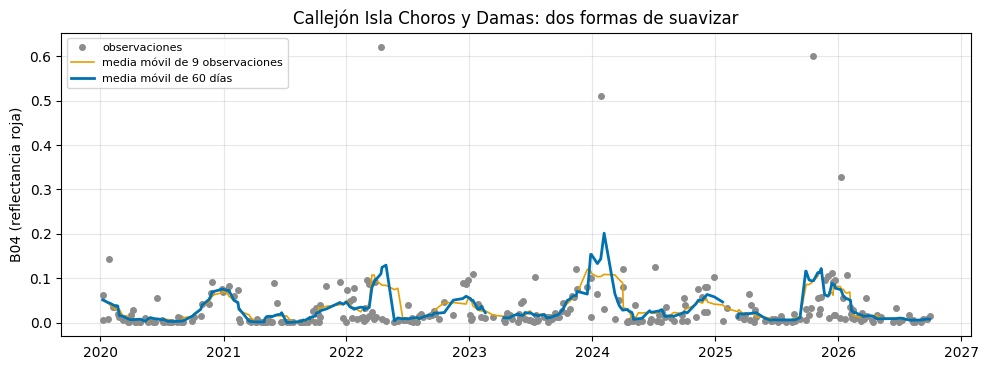

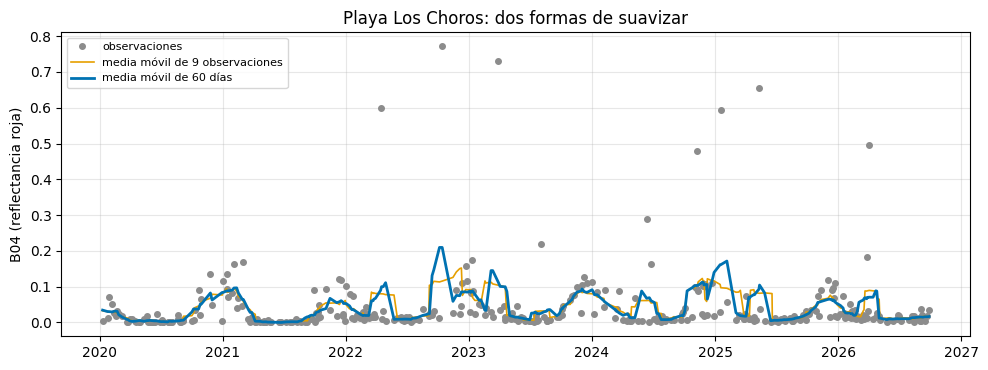

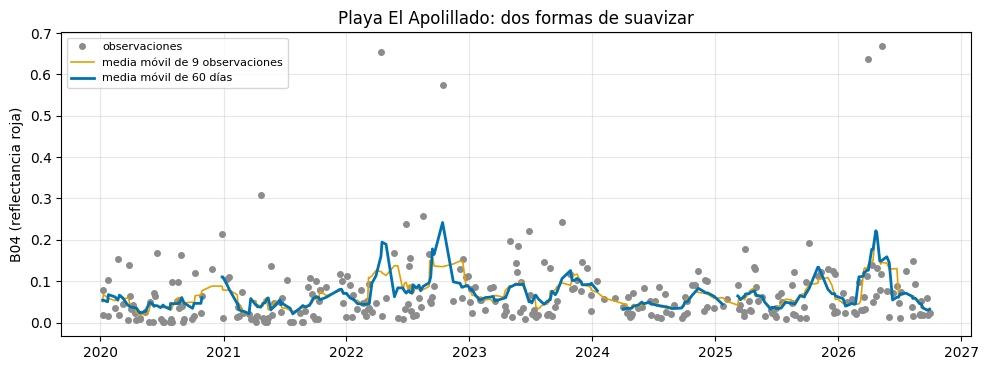

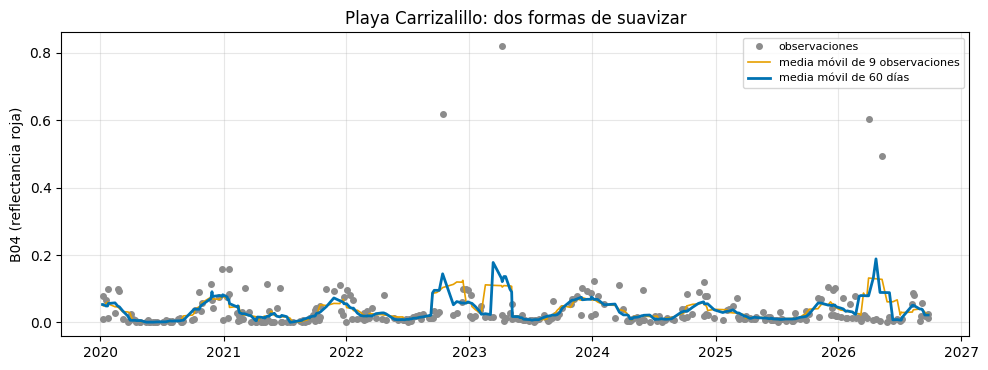

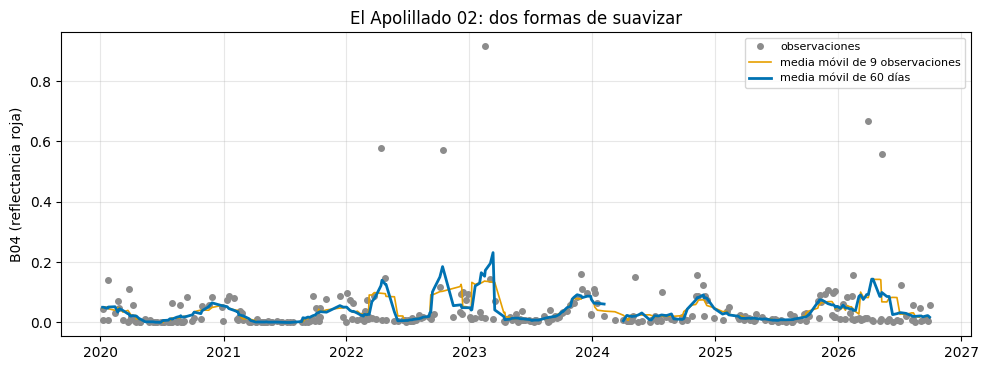

In [21]:
puntos = {
    "humedal_loschoros": "Humedal Quebrada Los Choros",
    "callejon": "Callejón Isla Choros y Damas",
    "playa_loschoros": "Playa Los Choros",
    "elapolillado": "Playa El Apolillado",
    "carrizalillo": "Playa Carrizalillo",
    "elapolillado02": "El Apolillado 02",
}
ventana_dias = "60D"   # ventana en días de calendario
ventana_obs = 9        # ventana en número de observaciones

for id_punto, nombre_punto in puntos.items():
    serie = tabla[tabla["id"] == id_punto].set_index("fecha")["b04"].dropna()

    if serie.empty:
        print(f"{nombre_punto}: sin datos de B04, se omite")
        continue

    serie.index = pd.to_datetime(serie.index)
    serie = serie.sort_index()

    movil_dias = serie.rolling(ventana_dias, min_periods=3, center=True).mean()
    movil_obs = serie.rolling(ventana_obs, min_periods=3, center=True).mean()

    fig, eje = plt.subplots(figsize=(10, 3.8))
    eje.plot(serie.index, serie, "o", markersize=4, color="0.55", label="observaciones")
    eje.plot(movil_obs.index, movil_obs, color="#E69F00", linewidth=1.2,
             label=f"media móvil de {ventana_obs} observaciones")
    eje.plot(movil_dias.index, movil_dias, color="#0072B2", linewidth=2,
             label=f"media móvil de {ventana_dias[:-1]} días")
    eje.set_ylabel("B04 (reflectancia roja)")
    eje.set_title(f"{nombre_punto}: dos formas de suavizar")
    eje.legend(fontsize=8)
    eje.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 4. Tendencia lineal, y qué puede decir un solo año

Se calcula una tendencia lineal para cada combinación de punto de muestreo y variable (B04, NDCI, NDVI y NDWI), y los resultados (número de datos, pendiente anual, R² y valor p) se guardan en la tabla tendencias. Al final se muestra una tabla resumen con la pendiente por año de cada variable en cada punto: los valores positivos indican que la variable aumenta con el tiempo y los negativos que disminuye. Así se pueden comparar de un vistazo las tendencias entre sitios.

In [22]:
filas = []
for id_punto in tabla["id"].unique():
    for variable in VARIABLES:
        tendencia = tendencia_lineal(tabla[tabla["id"] == id_punto].set_index("fecha")[variable].dropna())
        filas.append({"punto": id_punto, "variable": variable, "n": tendencia.n,
                      "pendiente_por_año": tendencia.pendiente_anual, "r2": tendencia.r2, "p": tendencia.p_valor})
tendencias = pd.DataFrame(filas)
tendencias.pivot(index="punto", columns="variable", values="pendiente_por_año").round(3)

variable,b04,ndci,ndvi,ndwi
punto,,,,
callejon,0.002,-0.019,-0.008,0.009
carrizalillo,0.002,-0.014,-0.018,-0.007
elapolillado,0.004,-0.012,-0.007,-0.028
elapolillado02,0.003,-0.016,-0.007,-0.009
humedal_loschoros,-0.001,0.001,0.003,-0.003
playa_loschoros,0.003,-0.017,-0.011,-0.005


Para cada uno de los seis puntos de muestreo se grafica la serie temporal de NDCI y se ajustan tendencias lineales en tres tramos distintos: los 12 meses completos, octubre a marzo y abril a septiembre. Cada tramo aparece con su propio color y la leyenda muestra la pendiente anual, el R² y el valor p de cada ajuste. Así se puede comparar entre sitios cómo cambia la tendencia según el periodo que se analice. Si un punto no tiene datos, o un tramo tiene menos de tres fechas, se omite y se imprime un aviso.


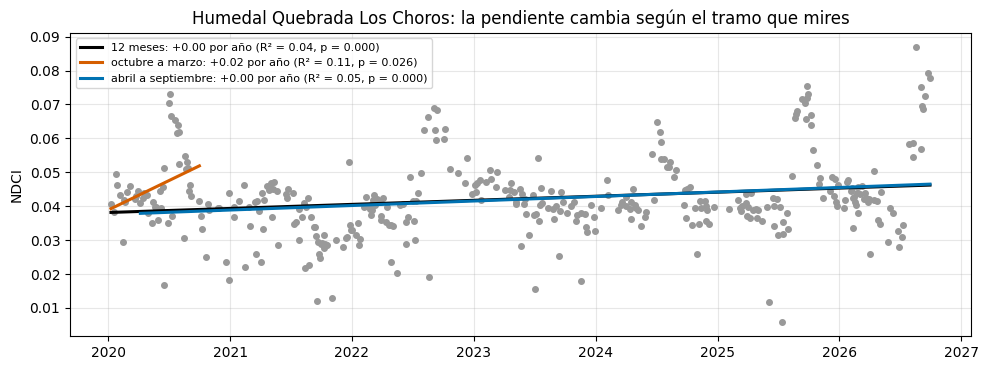

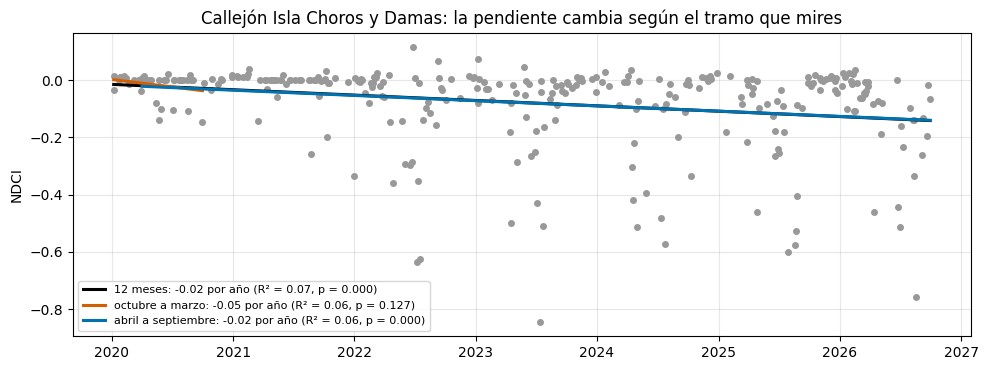

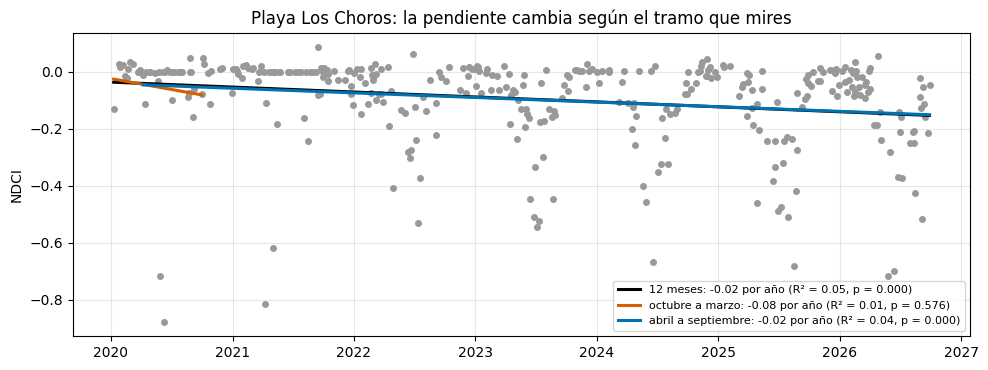

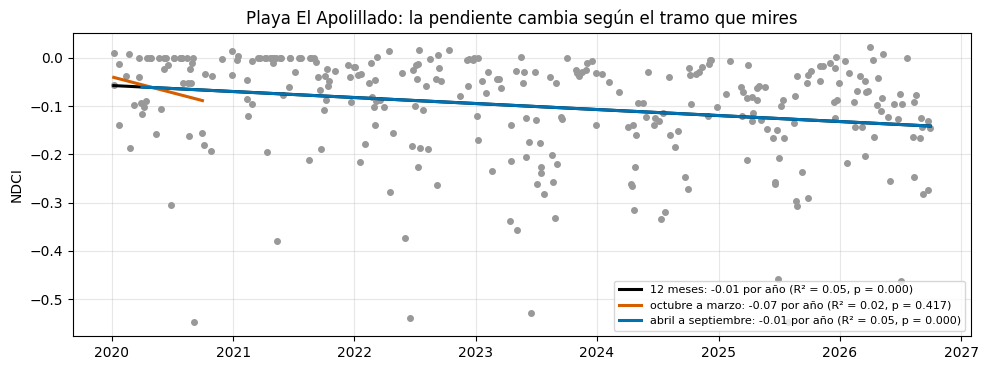

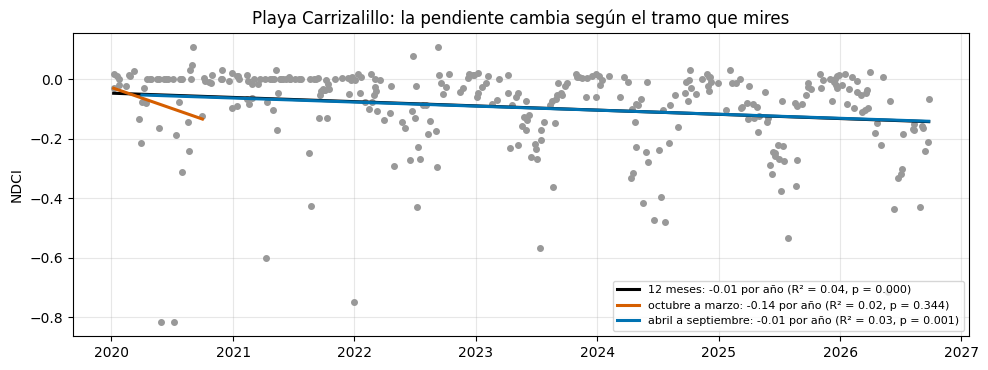

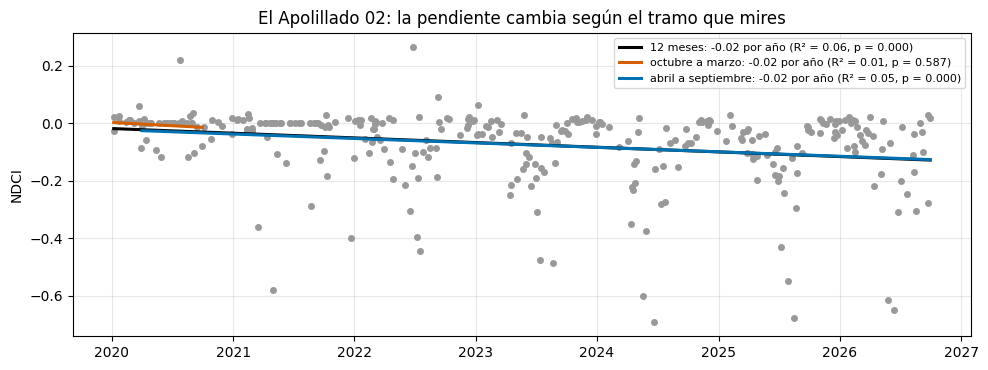

In [20]:
puntos = {
    "humedal_loschoros": "Humedal Quebrada Los Choros",
    "callejon": "Callejón Isla Choros y Damas",
    "playa_loschoros": "Playa Los Choros",
    "elapolillado": "Playa El Apolillado",
    "carrizalillo": "Playa Carrizalillo",
    "elapolillado02": "El Apolillado 02",
}
colores_tramos = ["#000000", "#D55E00", "#0072B2"]

for id_punto, nombre_punto in puntos.items():
    serie = tabla[tabla["id"] == id_punto].set_index("fecha")["ndci"].dropna()

    if serie.empty:
        print(f"{nombre_punto}: sin datos de NDCI, se omite")
        continue

    tramos = {
        "12 meses": serie,
        "octubre a marzo": serie.loc[:"2020-10-01"],
        "abril a septiembre": serie.loc["2020-04-01":],
    }

    fig, eje = plt.subplots(figsize=(10, 3.8))
    eje.plot(serie.index, serie, "o", markersize=4, color="0.6")

    for (nombre, tramo), color in zip(tramos.items(), colores_tramos):
        if len(tramo) < 3:
            print(f"{nombre_punto} – '{nombre}': muy pocos datos ({len(tramo)}), se omite")
            continue
        tendencia = tendencia_lineal(tramo)
        eje.plot(tendencia.ajuste.index, tendencia.ajuste, color=color, linewidth=2.2,
                 label=f"{nombre}: {tendencia.pendiente_anual:+.2f} por año "
                       f"(R² = {tendencia.r2:.2f}, p = {tendencia.p_valor:.3f})")

    eje.set_ylabel("NDCI")
    eje.set_title(f"{nombre_punto}: la pendiente cambia según el tramo que mires")
    eje.legend(fontsize=8)
    eje.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 5. Patrones estacionales

Se arma un mapa de calor por variable (NDWI, NDCI, B04 y NDVI) que muestra la mediana mensual de cada punto de muestreo. Cada fila es un sitio y cada columna un mes, ordenados de octubre a septiembre. El color indica el valor típico de la variable en ese mes, juntando todos los años. Así se ve de un vistazo el ciclo estacional de cada sitio y las diferencias entre sitios.

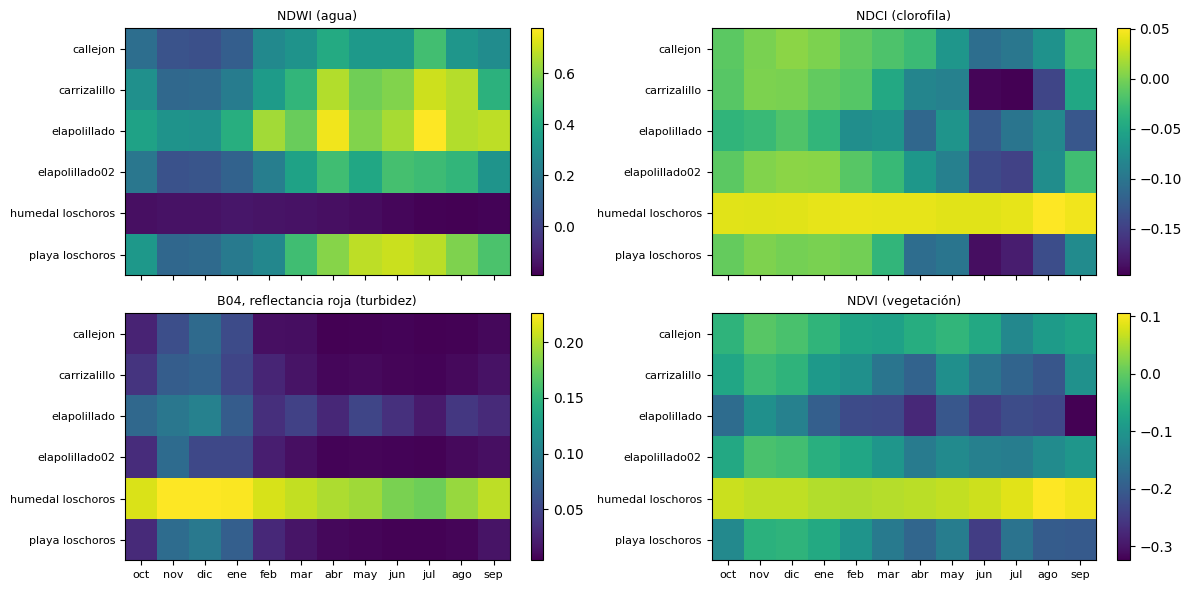

In [23]:
meses = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
nombres_meses = ["oct", "nov", "dic", "ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep"]
fig, ejes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for eje, variable in zip(ejes.ravel(), VARIABLES):
    mediana_mes = tabla.groupby(["id", tabla["fecha"].dt.month])[variable].median().unstack().reindex(columns=meses)
    mediana_mes = mediana_mes.loc[orden]
    imagen = eje.imshow(mediana_mes.values, aspect="auto", cmap="viridis")
    eje.set_yticks(range(len(orden)), labels=[p.replace("_", " ") for p in orden], fontsize=8)
    eje.set_xticks(range(12), labels=nombres_meses, fontsize=8)
    eje.set_title(ETIQUETAS[variable], fontsize=9)
    plt.colorbar(imagen, ax=eje, fraction=0.04)
plt.tight_layout()
plt.show()

El humedal de Los Choros se comporta distinto a todos los demás sitios en las cuatro variables: tiene NDWI bajo y B04, NDVI y NDCI altos durante todo el año. Eso calza con un píxel dominado por suelo o vegetación más que por agua abierta. Por lo mismo, ahí el NDCI no debería leerse como clorofila en el agua.

En los sitios marinos aparece un patrón estacional bastante claro:

Primavera-verano (oct–feb): el NDCI y el B04 son más altos, lo que sugiere más clorofila y turbidez. Esto podría coincidir con la temporada de surgencia más intensa en la zona.
Otoño-invierno (abr–ago): el NDWI es más alto y el NDCI baja, sobre todo en Carrizalillo y Playa Los Choros en junio y julio.

El Apolillado tiene el NDVI más bajo y el NDWI más alto entre los sitios marinos, es decir, la señal de agua más “limpia” del grupo.

Estas son medianas que agrupan varios años y no controlan efectos como nubes, oleaje o reflejo solar. Por eso conviene tomarlas como patrones descriptivos, no como conclusiones.

Para cada punto de muestreo se agrupan todas las observaciones de B04 (reflectancia roja) según el mes del año, mezclando los distintos años, y se calcula la media, la desviación estándar y el número de datos de cada mes. Primero se imprime esa tabla resumen y luego se grafica el ciclo anual de octubre a septiembre: cada punto es la media mensual y las barras muestran ± 1 desviación estándar. El título indica cuántas observaciones tiene cada mes, porque los meses con pocos datos dan promedios menos confiables.


Humedal Quebrada Los Choros
mes        1       2       3       4       5       6       7       8       9       10      11      12
media   0.230   0.212   0.213   0.205   0.183   0.177   0.174   0.196   0.202   0.212   0.255   0.226
desv    0.023   0.022   0.025   0.047   0.030   0.034   0.029   0.074   0.026   0.015   0.116   0.033
n      22.000  30.000  37.000  38.000  32.000  32.000  40.000  33.000  36.000  25.000  20.000  27.000


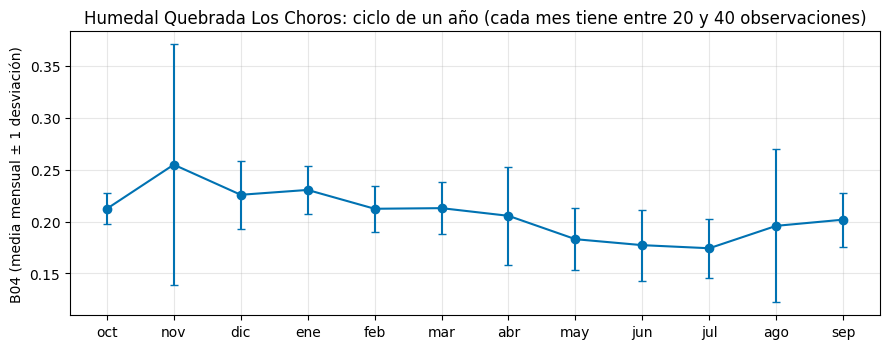


Callejón Isla Choros y Damas
mes        1       2       3       4       5       6       7       8       9       10      11      12
media   0.077   0.020   0.023   0.031   0.010   0.012   0.012   0.007   0.013   0.055   0.058   0.066
desv    0.111   0.016   0.029   0.109   0.018   0.017   0.027   0.008   0.012   0.133   0.030   0.038
n      26.000  24.000  30.000  33.000  25.000  26.000  35.000  30.000  27.000  19.000  18.000  22.000


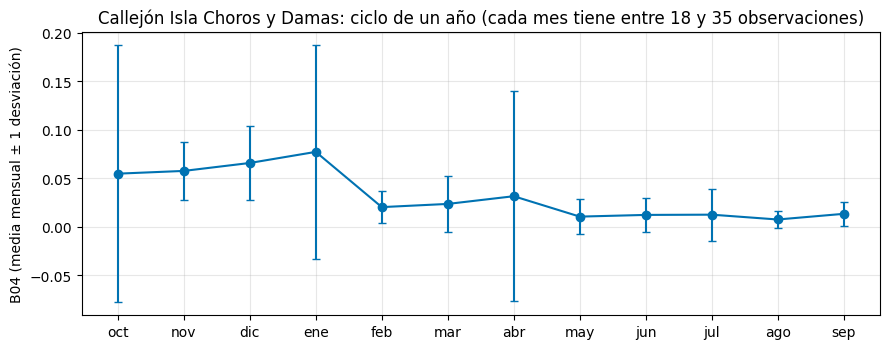


Playa Los Choros
mes        1       2       3       4       5       6       7       8       9       10      11      12
media   0.079   0.037   0.047   0.043   0.034   0.021   0.006   0.015   0.018   0.066   0.089   0.071
desv    0.108   0.030   0.124   0.128   0.121   0.056   0.005   0.037   0.017   0.159   0.098   0.049
n      29.000  30.000  36.000  35.000  29.000  32.000  34.000  34.000  32.000  22.000  20.000  28.000


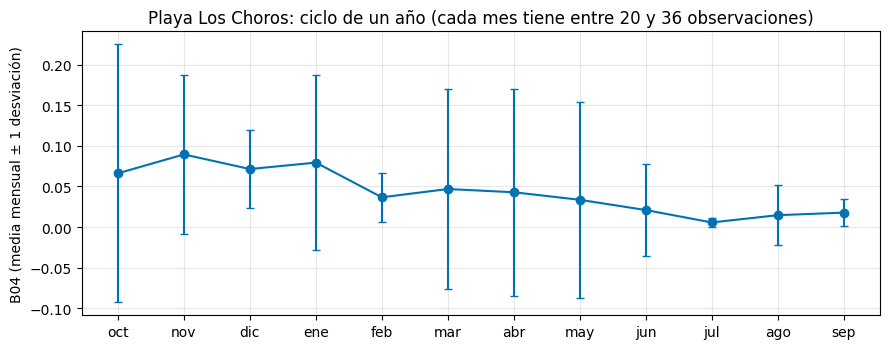


Playa El Apolillado
mes        1       2       3       4       5       6       7       8       9       10      11      12
media   0.065   0.044   0.077   0.068   0.087   0.057   0.042   0.062   0.043   0.112   0.093   0.085
desv    0.034   0.032   0.115   0.121   0.128   0.060   0.043   0.057   0.039   0.134   0.030   0.053
n      20.000  20.000  29.000  33.000  28.000  29.000  33.000  33.000  28.000  17.000  13.000  26.000


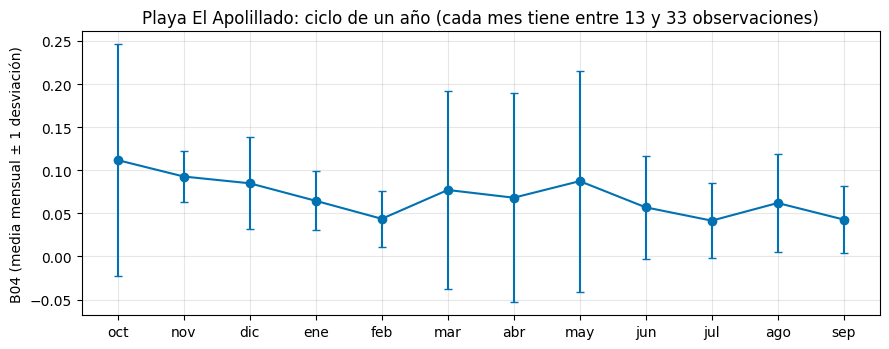


Playa Carrizalillo
mes        1       2       3       4       5       6       7       8       9       10      11      12
media   0.053   0.033   0.044   0.037   0.033   0.012   0.007   0.016   0.020   0.068   0.064   0.062
desv    0.041   0.027   0.111   0.146   0.089   0.020   0.007   0.022   0.014   0.135   0.034   0.041
n      26.000  24.000  29.000  31.000  31.000  28.000  34.000  30.000  32.000  19.000  17.000  29.000


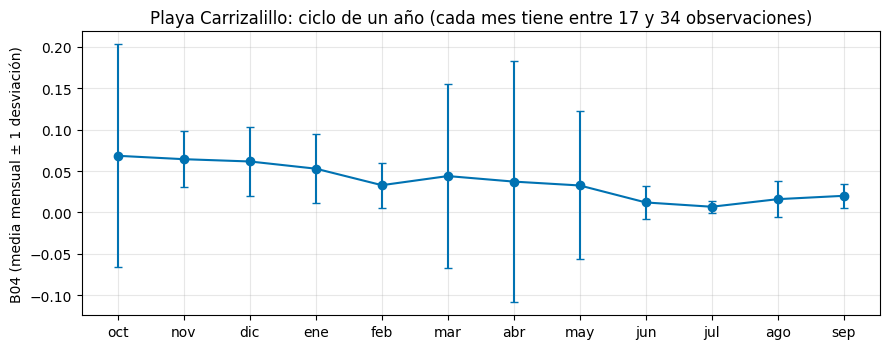


El Apolillado 02
mes        1       2       3       4       5       6       7       8       9       10     11      12
media   0.052   0.064   0.049   0.030   0.034   0.007   0.014   0.014   0.019   0.066   0.08   0.058
desv    0.040   0.173   0.124   0.104   0.108   0.008   0.028   0.017   0.021   0.133   0.04   0.038
n      24.000  27.000  29.000  32.000  27.000  27.000  33.000  31.000  30.000  17.000  18.00  25.000


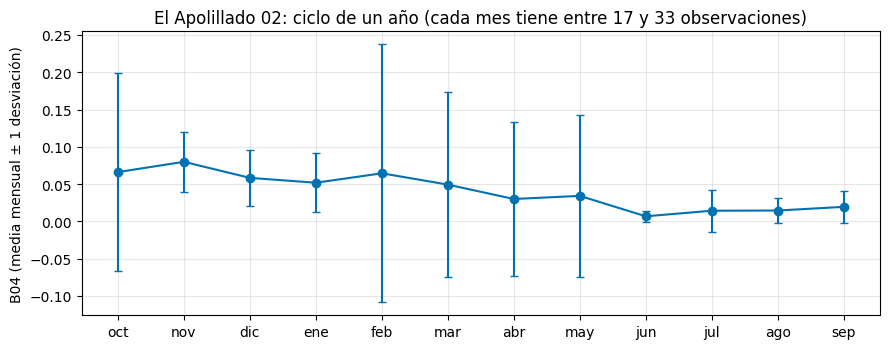

In [25]:
puntos = {
    "humedal_loschoros": "Humedal Quebrada Los Choros",
    "callejon": "Callejón Isla Choros y Damas",
    "playa_loschoros": "Playa Los Choros",
    "elapolillado": "Playa El Apolillado",
    "carrizalillo": "Playa Carrizalillo",
    "elapolillado02": "El Apolillado 02",
}
meses = [10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9]
nombres_meses = ["oct", "nov", "dic", "ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep"]

for id_punto, nombre_punto in puntos.items():
    serie = tabla[tabla["id"] == id_punto].set_index("fecha")["b04"].dropna()

    if serie.empty:
        print(f"{nombre_punto}: sin datos de B04, se omite")
        continue

    serie.index = pd.to_datetime(serie.index)
    por_mes = serie.groupby(serie.index.month.rename("mes"))
    clima = por_mes.agg(media="mean", desv="std", n="size").reindex(range(1, 13))

    print(f"\n{nombre_punto}")
    print(clima.round(3).T.to_string())

    orden_meses = clima.reindex(meses)
    n_min = int(orden_meses["n"].min(skipna=True))
    n_max = int(orden_meses["n"].max(skipna=True))

    fig, eje = plt.subplots(figsize=(9, 3.6))
    eje.errorbar(range(12), orden_meses["media"], yerr=orden_meses["desv"],
                 fmt="o-", color="#0072B2", capsize=3)
    eje.set_xticks(range(12), labels=nombres_meses)
    eje.set_ylabel("B04 (media mensual ± 1 desviación)")
    eje.set_title(f"{nombre_punto}: ciclo de un año "
                  f"(cada mes tiene entre {n_min} y {n_max} observaciones)")
    eje.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

El Humedal Quebrada Los Choros vuelve a separarse claramente del resto. Su reflectancia roja (B04) es varias veces mayor, entre 0.17 y 0.26, lo que calza con un píxel dominado por suelo o vegetación más que por agua. Tiene un ciclo anual suave: valores más altos en primavera-verano (máximo en noviembre) y más bajos en invierno (junio-julio).

Los sitios marinos tienen valores bajos de B04 (entre 0 y 0.11) y comparten un patrón estacional bastante consistente:

Primavera-verano (octubre a enero): valores más altos, lo que sugiere más turbidez o material en suspensión.
Invierno (junio a septiembre): valores mínimos, cercanos a cero en Carrizalillo, Playa Los Choros, El Apolillado 02 y el Callejón.

En el Callejón la caída es especialmente marcada después de enero. Playa El Apolillado es la excepción: tiene los valores más altos entre los sitios marinos y una estacionalidad menos clara, con un máximo en octubre y otro secundario en mayo.

Hay que leer con cuidado las barras de error. En varios meses (sobre todo octubre y de marzo a mayo) la desviación estándar es mayor que la media, y las barras llegan a valores negativos, que no tienen sentido físico para una reflectancia. Eso indica que unas pocas observaciones extremas, probablemente por nubes, reflejo solar o espuma, están inflando la media y la dispersión. En cambio, los meses de invierno muestran barras estrechas, es decir, condiciones más homogéneas. Además, octubre y noviembre son los meses con menos observaciones (entre 13 y 25), así que sus promedios son menos confiables

Se asigna a cada fecha la estación del año del hemisferio sur: verano de diciembre a febrero, otoño de marzo a mayo, invierno de junio a agosto y primavera de septiembre a noviembre. Esa estación se guarda en una nueva columna, estacion. Luego se calcula la mediana de NDWI, NDCI, B04 y NDVI para cada estación, juntando los seis puntos de muestreo, y se cuenta cuántas observaciones con dato de B04 hay en cada una. El resultado es una tabla que muestra el ritmo estacional general de las cuatro variables. Como mezcla sitios marinos con el humedal, sirve solo como una vista de conjunto y no para comparar sitios ni interpretar valores absolutos.

In [26]:
estaciones = {12: "verano", 1: "verano", 2: "verano", 3: "otoño", 4: "otoño", 5: "otoño",
              6: "invierno", 7: "invierno", 8: "invierno", 9: "primavera", 10: "primavera", 11: "primavera"}
tabla["estacion"] = tabla["fecha"].dt.month.map(estaciones)
por_estacion = tabla.groupby(["estacion"])[["ndwi", "ndci", "b04", "ndvi"]].median().reindex(["verano", "otoño", "invierno", "primavera"])
n_estacion = tabla.dropna(subset=["b04"]).groupby("estacion").size().reindex(por_estacion.index).rename("n filas")
print("Mediana de los seis puntos juntos por estación (mezcla agua y humedal: solo para ver el ritmo)")
pd.concat([por_estacion.round(3), n_estacion], axis=1)

Mediana de los seis puntos juntos por estación (mezcla agua y humedal: solo para ver el ritmo)


,ndwi,ndci,b04,ndvi,n filas
estacion,,,,,
verano,0.170,0.001,0.061,-0.061,459
otoño,0.409,-0.031,0.016,-0.101,564
invierno,0.495,-0.081,0.011,-0.118,574
primavera,0.226,-0.009,0.040,-0.062,410


Las cuatro variables muestran un mismo ritmo estacional, con el invierno y el verano como extremos opuestos:

NDWI sube de forma marcada desde el verano (0.17) hasta el invierno (0.50) y vuelve a bajar en primavera (0.23). La señal de agua “limpia” es más fuerte en invierno.
NDCI y B04 hacen lo contrario: alcanzan su máximo en verano (0.001 y 0.070) y su mínimo en invierno (−0.075 y 0.013). Eso sugiere más clorofila y más turbidez en los meses cálidos, y aguas más claras en invierno.
NDVI es negativo en todas las estaciones, como se espera cuando la mayoría de los píxeles son agua. Es menos negativo en verano y primavera, y más negativo en invierno.

En conjunto, la tabla resume lo que ya se veía punto por punto: en primavera-verano hay más material en suspensión y clorofila, y en otoño-invierno el agua es más clara.

El número de observaciones también varía según la estación: hay más en otoño e invierno (476 y 483) que en primavera (345), probablemente porque en primavera hay menos imágenes sin nubes. Como la tabla mezcla los sitios marinos con el humedal, estos valores sirven para ver el ritmo general, no para interpretar magnitudes.

## 6. Anomalías con un año de datos: z-score

Una **anomalía** es un valor que se aleja de lo esperado. El z-score la mide en desviaciones estándar: `z = (valor - media) / desviación`. Un |z| mayor que 2 es poco habitual. Hay dos formas de definir "lo esperado":

* `referencia="mes"`: la media y la desviación **del mismo mes del año**. Quita el ciclo estacional (un valor de enero se compara con enero), pero necesita muchos años.
* `referencia="total"`: la media y la desviación **de toda la serie**. Mezcla estación con anomalía.

Con un año de datos, cada mes tiene entre 2 y 11 observaciones, todas del mismo año. Veamos qué pasa con B04, contando las fechas con |z| > 2 con cada referencia:

Se buscan valores anómalos de B04 en cada punto de muestreo usando puntajes z, que miden cuántas desviaciones estándar se aleja cada observación del valor de referencia. Para cada sitio se calculan dos versiones:

‘total’: compara cada dato con la media y la desviación de toda la serie.
‘mes’: compara cada dato con la media y la desviación de su propio mes del año, es decir, descontando el ciclo estacional.

La tabla muestra, para cada punto, el número de observaciones (n), cuántas superan |z| > 2 con cada referencia y el valor z más alto que se obtuvo con cada una.

In [27]:
filas = []
for id_punto in tabla["id"].unique():
    serie = tabla[tabla["id"] == id_punto].set_index("fecha")["b04"].dropna()
    z_total = anomalias_zscore(serie, referencia="total")
    z_mes = anomalias_zscore(serie, referencia="mes")
    filas.append({"punto": id_punto, "n": len(serie), "|z| > 2 con 'total'": int((z_total.abs() > 2).sum()),
                  "|z| > 2 con 'mes'": int((z_mes.abs() > 2).sum()),
                  "z máximo 'total'": round(z_total.max(), 1), "z máximo 'mes'": round(z_mes.max(), 1)})
pd.DataFrame(filas).set_index("punto")

,n,|z| > 2 con 'total',|z| > 2 con 'mes',z máximo 'total',z máximo 'mes'
punto,,,,,
callejon,315,4,17,9.2,5.4
carrizalillo,330,4,14,10.5,5.4
elapolillado,309,8,13,7.3,4.9
elapolillado02,320,5,15,10.1,5.3
humedal_loschoros,372,10,18,10.9,5.1
playa_loschoros,361,8,15,8.0,5.5


Usar el mes como referencia detecta más anomalías (entre 13 y 18 por sitio) que usar la serie completa (entre 4 y 10). Esto pasa porque, al quitar el ciclo estacional, un valor que parece normal en el contexto de todo el año puede ser inusual para su mes. Por ejemplo, un valor moderadamente alto en invierno, cuando la variabilidad es muy baja, queda marcado como anomalía. Con unas 300 a 370 observaciones por sitio, si los datos fueran normales se esperarían alrededor de 15 a 18 valores con |z| > 2, así que la referencia mensual da cifras cercanas a lo esperado.

En cambio, el z máximo es mucho más alto con la referencia ‘total’ (entre 7.3 y 10.9) que con ‘mes’ (entre 4.9 y 5.5). Valores de z tan extremos indican unas pocas observaciones muy fuera de rango, probablemente por nubes, reflejo solar o espuma, como ya sugerían las barras de error de los gráficos mensuales. Esos valores caen en meses que ya tienen alta variabilidad, por eso su z se reduce al compararlos con su propio mes. Además, estos valores extremos inflan la desviación estándar de la serie completa, y eso explica en parte por qué la referencia ‘total’ marca menos anomalías.

El humedal es el sitio con más anomalías y el z máximo ‘total’ más alto. Los sitios marinos se comportan de forma bastante similar entre sí.

Para cada punto de muestreo se calcula el puntaje z de B04 respecto de la media y la desviación de toda la serie, y se marcan como atípicas las fechas con |z| > 2. Cada figura tiene dos paneles: arriba, la serie de B04 con las fechas atípicas destacadas en naranjo; abajo, el puntaje z de cada fecha con los umbrales de ±2 como líneas punteadas. Así se identifican fácilmente las fechas con turbidez inusual, que pueden corresponder a eventos reales o a imágenes afectadas por nubes, reflejo solar o espuma.

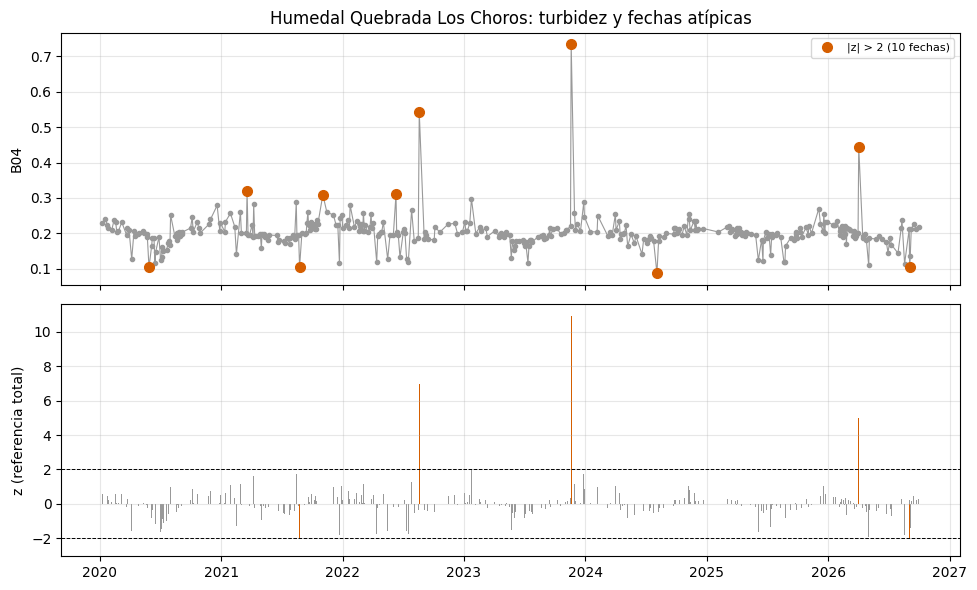

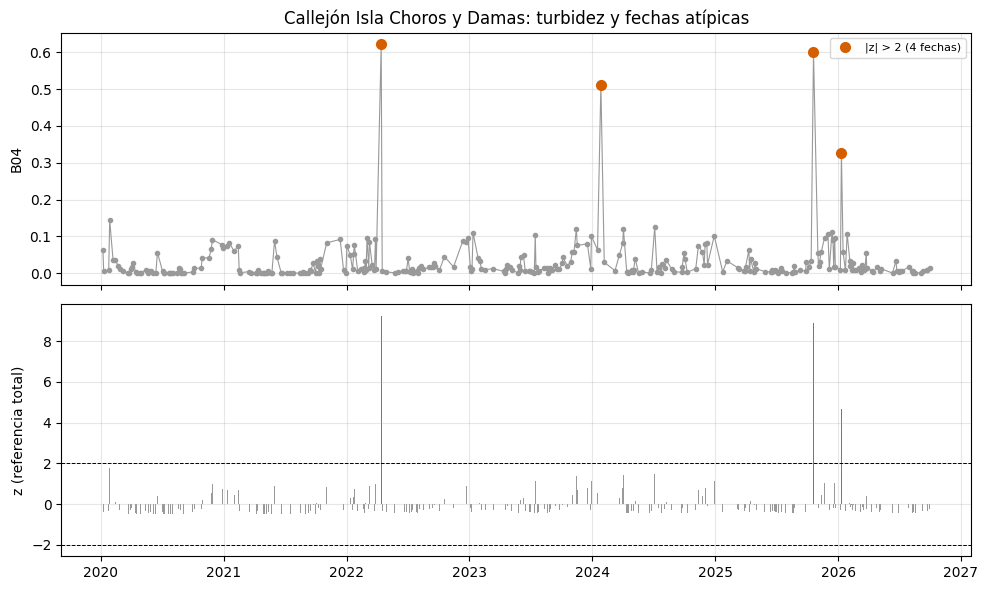

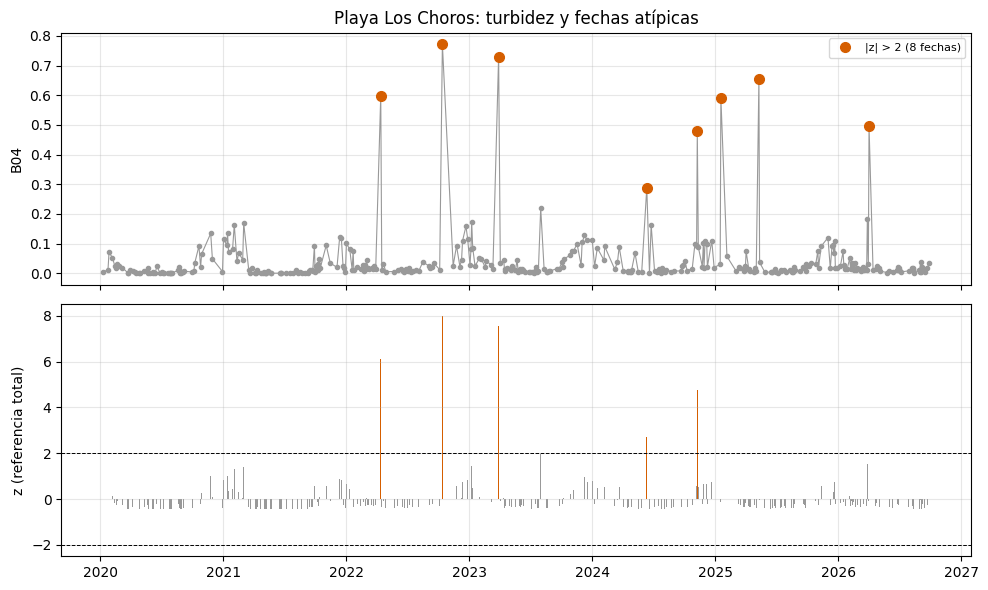

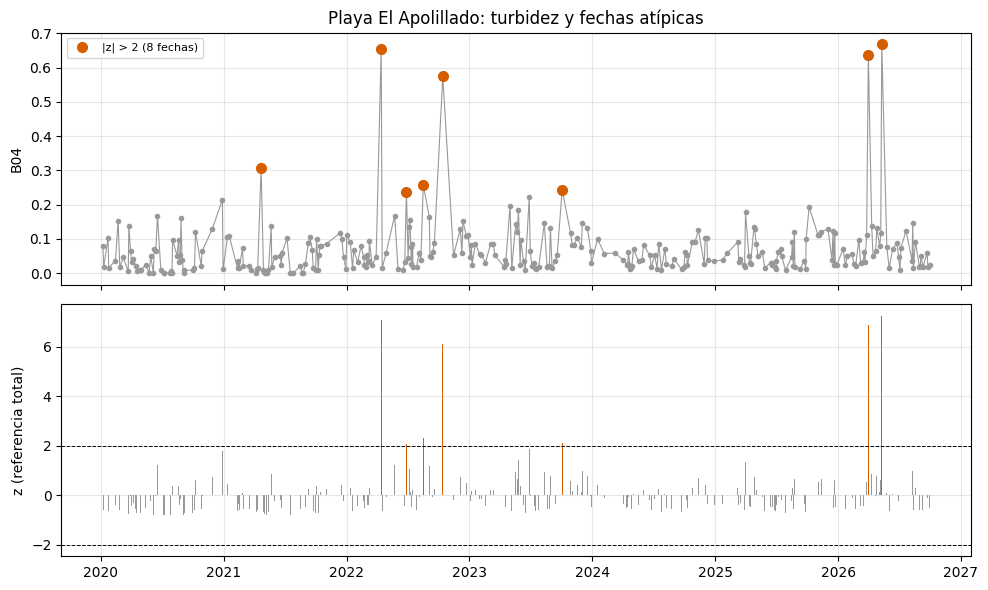

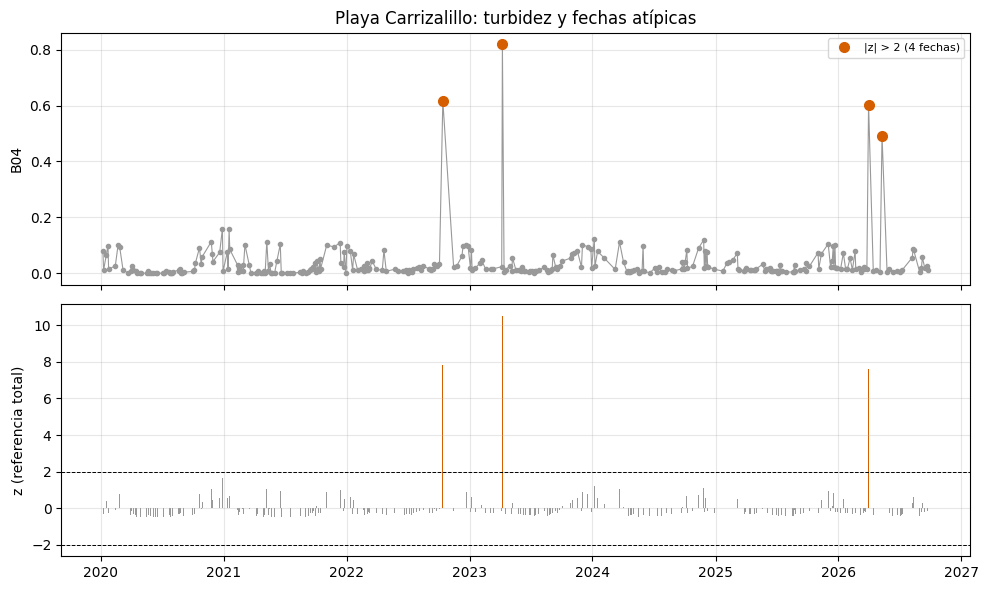

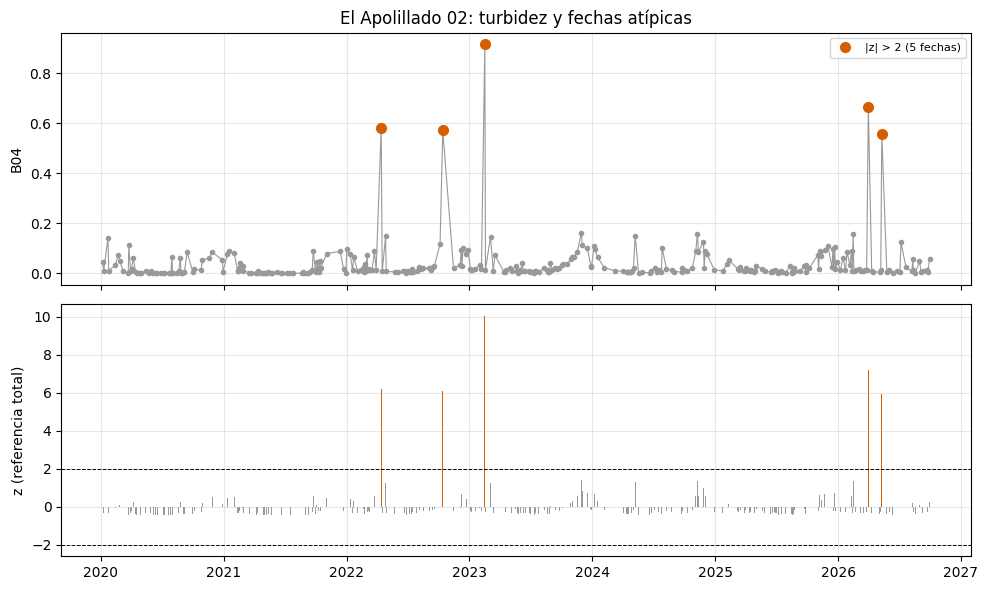

In [28]:
puntos = {
    "humedal_loschoros": "Humedal Quebrada Los Choros",
    "callejon": "Callejón Isla Choros y Damas",
    "playa_loschoros": "Playa Los Choros",
    "elapolillado": "Playa El Apolillado",
    "carrizalillo": "Playa Carrizalillo",
    "elapolillado02": "El Apolillado 02",
}

for id_punto, nombre_punto in puntos.items():
    serie = tabla[tabla["id"] == id_punto].set_index("fecha")["b04"].dropna()

    if serie.empty:
        print(f"{nombre_punto}: sin datos de B04, se omite")
        continue

    serie.index = pd.to_datetime(serie.index)
    serie = serie.sort_index()

    z = anomalias_zscore(serie, referencia="total")
    raras = z[z.abs() > 2]

    fig, ejes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    ejes[0].plot(serie.index, serie, "o-", color="0.6", markersize=3, linewidth=0.8)
    ejes[0].plot(raras.index, serie[raras.index], "o", color="#D55E00", markersize=7,
                 label=f"|z| > 2 ({len(raras)} fechas)")
    ejes[0].set_ylabel("B04")
    ejes[0].legend(fontsize=8)
    ejes[1].bar(z.index, z, width=2, color=np.where(z.abs() > 2, "#D55E00", "0.6"))
    ejes[1].axhline(2, color="k", linewidth=0.7, linestyle="--")
    ejes[1].axhline(-2, color="k", linewidth=0.7, linestyle="--")
    ejes[1].set_ylabel("z (referencia total)")
    for eje in ejes:
        eje.grid(alpha=0.3)
    ejes[0].set_title(f"{nombre_punto}: turbidez y fechas atípicas")
    plt.tight_layout()
    plt.show()

En los sitios marinos, la reflectancia roja se mantiene casi siempre entre 0 y 0.15. Las fechas atípicas aparecen como picos aislados de entre 0.5 y 0.9, con z de 5 a 10, y la serie vuelve a su nivel normal en la imagen siguiente. Varios de esos picos coinciden en la misma fecha en sitios cercanos, por ejemplo abril y octubre de 2022, comienzos de 2023 y abril-mayo de 2026. Eso sugiere que se deben más a nubes, bruma o reflejo solar sobre toda la escena que a eventos reales de turbidez. Por eso conviene revisar esas imágenes antes de interpretarlas o excluirlas del análisis.

El humedal es distinto: su nivel base es más alto (alrededor de 0.2) y tiene anomalías hacia arriba y hacia abajo, algunas apenas sobre el umbral de ±2. Además del ruido de las imágenes, su variabilidad parece reflejar cambios propios del sitio, como en el agua, el suelo o la vegetación.

Se toman las fechas atípicas de B04 en Carrizalillo (|z| > 2) y se arma una tabla de revisión con su valor de B04, el porcentaje de nubes de la escena Sentinel-2, la fracción de píxeles válidos en el punto y el puntaje z. Así se puede ver si las anomalías coinciden con imágenes de mala calidad.

In [29]:
revision = tabla[(tabla["id"] == "carrizalillo") & tabla["fecha"].isin(raras.index)][["fecha", "b04", "nubes_escena", "pixeles_validos"]]
revision = revision.assign(z=raras.values)
revision.round({"b04": 3, "nubes_escena": 1, "pixeles_validos": 2, "z": 1})

,fecha,b04,nubes_escena,pixeles_validos,z
1318,2022-04-13 14:37:31.024,NaN,24.2,0.0,6.2
1391,2022-10-13 14:47:31.024,0.617,72.6,0.7,6.1
1440,2023-02-15 14:47:29.024,NaN,69.9,0.0,10.1
1902,2026-03-31 14:47:29.024,0.602,66.6,1.0,7.2
1920,2026-05-10 14:47:29.024,0.493,68.2,1.0,5.9


Las cuatro fechas atípicas vienen de escenas muy nubladas, con entre 57 y 73 % de nubes. Aun así, la fracción de píxeles válidos en el punto es alta (entre 0.70 y 1.00), es decir, la máscara de nubes no los descartó. Esto refuerza la idea de que los picos de B04 se deben a nubes delgadas, bruma o bordes de nubes que no fueron detectados, más que a eventos reales de turbidez. Como el porcentaje de nubes se calcula para toda la escena y no para el punto, conviene confirmarlo mirando las imágenes de esas fechas.

Se toma la serie de B04 de Playa Los Choros, se calculan sus puntajes z respecto de toda la serie y se identifica la fecha con la anomalía más alta. Luego se imprime un resumen con el valor máximo de B04, su fecha, su puntaje z y la mediana de la serie, para ver cuánto se aleja ese valor de lo habitual. Al final se muestra la fila de esa fecha con B04, NDWI, el porcentaje de nubes de la escena y la fracción de píxeles válidos, para revisar si el pico podría deberse a una imagen de mala calidad.

In [30]:
b04_playa_loschoros = tabla[tabla["id"] == "playa_loschoros"].set_index("fecha")["b04"].dropna()
z_playa_loschoros = anomalias_zscore(b04_playa_loschoros, referencia="total")
fecha_max = z_playa_loschoros.idxmax()
print(f"Playa Los Choros: B04 máximo {b04_playa_loschoros.max():.3f} el {fecha_max:%Y-%m-%d} (z = {z_playa_loschoros.max():.1f}); mediana de la serie {b04_playa_loschoros.median():.4f}")
tabla[(tabla["id"] == "playa_loschoros") & (tabla["fecha"] == fecha_max)][["fecha", "b04", "ndwi", "nubes_escena", "pixeles_validos"]]

Playa Los Choros: B04 máximo 0.772 el 2022-10-13 (z = 8.0); mediana de la serie 0.0151


,fecha,b04,ndwi,nubes_escena,pixeles_validos
5347,2022-10-13 14:47:31.024,0.772,0.000567,72.570711,0.799718


## 7. Preparando el bloque 7: climatología y anomalías con Landsat

Se carga la serie de Landsat 8 y 9 para los puntos del área de estudio. Este archivo tiene la misma estructura que el de Sentinel-2, pero incluye la temperatura superficial ya calibrada (st_c, en °C). A cada fecha se le quita la hora de la toma, porque solo importa el día, y se aplica controlar_calidad_agua para descartar las observaciones que la reflectancia identifica como nube. Luego se extrae la serie de temperatura de Playa Carrizalillo. Las fechas nubladas quedan como NaN y no se rellenan.

El resultado muestra que, entre enero de 2020 y septiembre de 2026, el satélite pasó 255 veces sobre Carrizalillo, pero solo 74 de esas pasadas (alrededor del 29 %) tienen un dato válido de temperatura. Eso equivale a unas 11 observaciones por año. Las tres últimas, de septiembre de 2026, muestran temperaturas entre 15.5 y 16.7 °C.

In [32]:
landsat = pd.read_parquet(DATOS / "series_landsat_humboldt.parquet")
landsat["fecha"] = landsat["fecha"].dt.normalize()
landsat = controlar_calidad_agua(landsat)
st = landsat[landsat["id"] == "carrizalillo"].set_index("fecha")["st_c"].astype(float)
print(f"{len(st)} pasos del satélite, {st.notna().sum()} con dato; {st.index.min():%Y-%m-%d} a {st.index.max():%Y-%m-%d}")
st.dropna().tail(3)

255 pasos del satélite, 74 con dato; 2020-01-01 a 2026-09-30


,st_c
fecha,
2026-09-14,15.496613
2026-09-22,16.696350
2026-09-30,16.074280


Para cada localidad se construye la climatología mensual de la temperatura superficial del mar medida por Landsat, usando como periodo base los años completos 2020 a 2025. Las observaciones válidas se agrupan por mes del año, sin importar el año, y para cada mes se calculan la media, la desviación estándar y el número de datos. El gráfico muestra el ciclo anual típico de cada sitio: la línea es la temperatura media de cada mes y la banda sombreada es ± 1 desviación estándar. Sobre cada gráfico se indica cuántas observaciones tiene cada mes, porque con pocos años de datos algunos meses quedan con muy pocas fechas y sus promedios son menos confiables. Las climatologías quedan guardadas para calcular anomalías en el paso siguiente.

Humedal Quebrada Los Choros: 87 observaciones en 2020-2025, entre 4 y 10 por mes


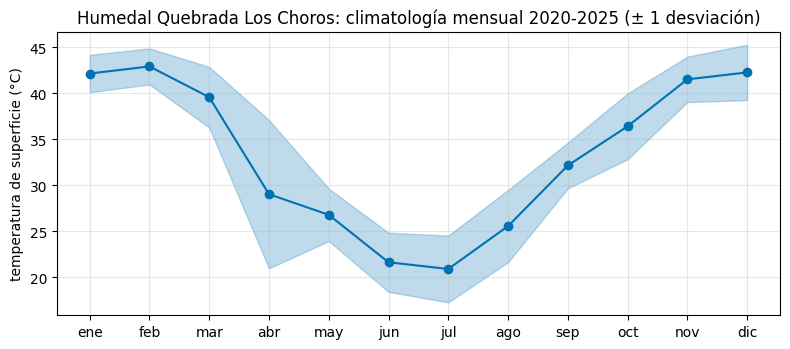

Callejón Isla Choros y Damas: 64 observaciones en 2020-2025, entre 2 y 9 por mes


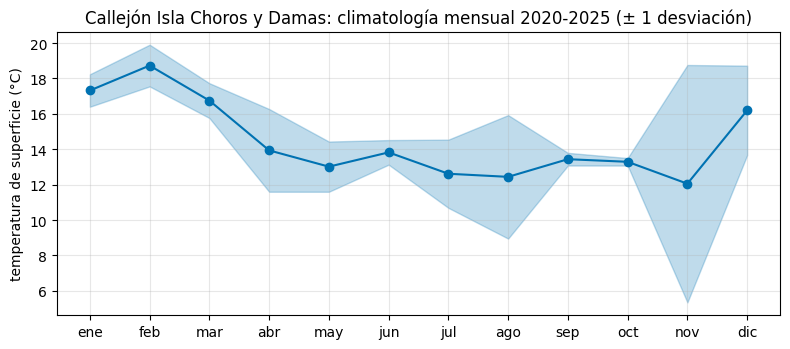

Playa Los Choros: 73 observaciones en 2020-2025, entre 3 y 10 por mes


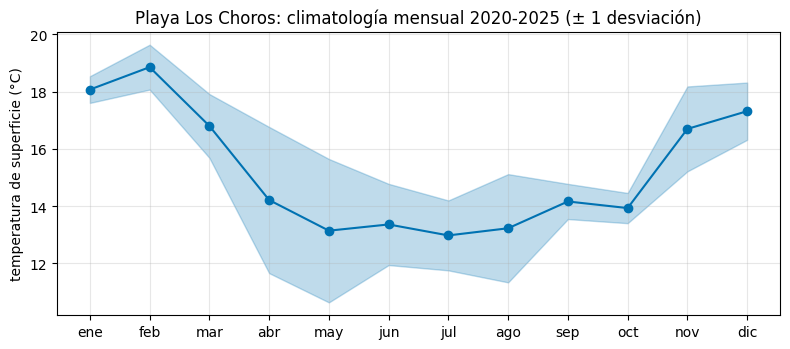

Playa El Apolillado: 11 observaciones en 2020-2025, entre 0 y 3 por mes


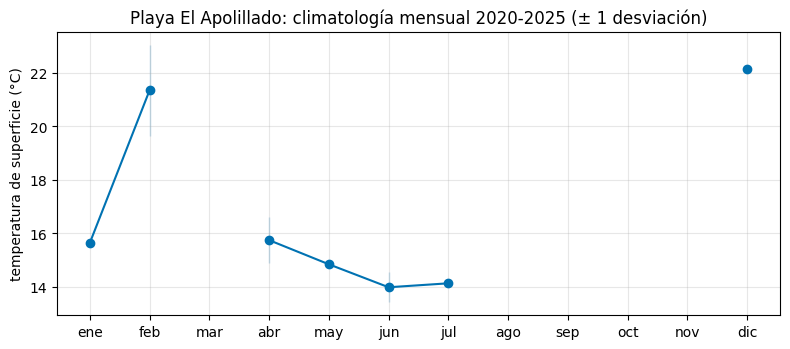

Playa Carrizalillo: 63 observaciones en 2020-2025, entre 3 y 10 por mes


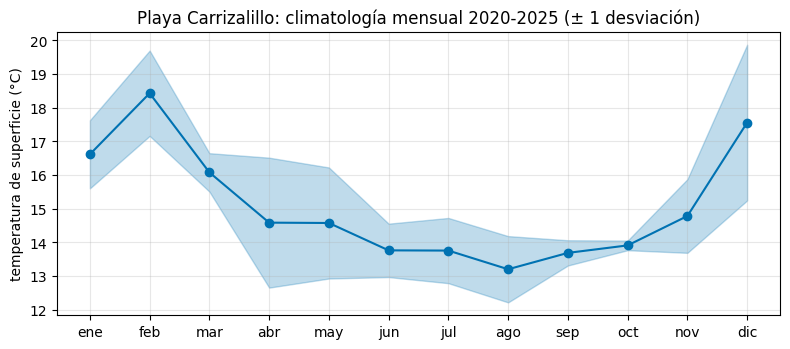

El Apolillado 02: 60 observaciones en 2020-2025, entre 2 y 9 por mes


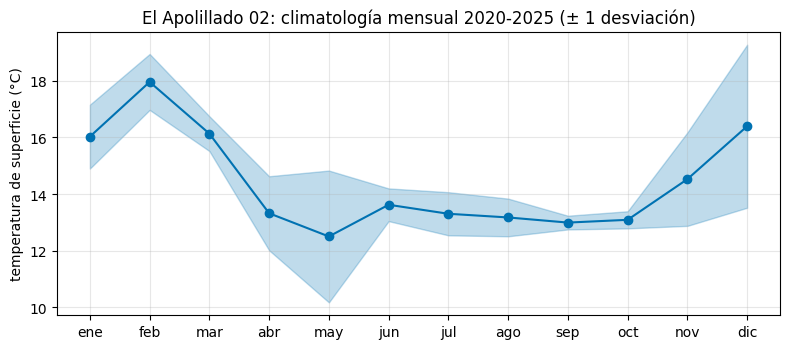

In [33]:
puntos = {
    "humedal_loschoros": "Humedal Quebrada Los Choros",
    "callejon": "Callejón Isla Choros y Damas",
    "playa_loschoros": "Playa Los Choros",
    "elapolillado": "Playa El Apolillado",
    "carrizalillo": "Playa Carrizalillo",
    "elapolillado02": "El Apolillado 02",
}
anio_inicio, anio_fin = "2020", "2025"   # años completos de la base
nombres_meses = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
climatologias = {}

for id_punto, nombre_punto in puntos.items():
    st_punto = landsat[landsat["id"] == id_punto].set_index("fecha")["st_c"].astype(float)
    base = st_punto.dropna().loc[anio_inicio:anio_fin]

    if base.empty:
        print(f"{nombre_punto}: sin datos de temperatura válidos, se omite")
        continue

    clima = (base.groupby(base.index.month.rename("mes"))
                 .agg(media="mean", desv="std", n="size")
                 .reindex(range(1, 13)))
    climatologias[id_punto] = clima

    n_mes = clima["n"].fillna(0).astype(int)
    print(f"{nombre_punto}: {len(base)} observaciones en {anio_inicio}-{anio_fin}, "
          f"entre {n_mes.min()} y {n_mes.max()} por mes")

    fig, eje = plt.subplots(figsize=(8, 3.6))
    eje.fill_between(range(1, 13), clima["media"] - clima["desv"], clima["media"] + clima["desv"],
                     alpha=0.25, color="#0072B2")
    eje.plot(range(1, 13), clima["media"], "o-", color="#0072B2")
    eje.set_xticks(range(1, 13), labels=nombres_meses)
    eje.set_ylabel("temperatura de superficie (°C)")
    eje.set_title(f"{nombre_punto}: climatología mensual {anio_inicio}-{anio_fin} (± 1 desviación)")
    eje.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

En los cuatro sitios marinos con buena cobertura (El Apolillado 02, Carrizalillo, Playa Los Choros y el Callejón) aparece un ciclo anual claro y muy parecido entre sitios:

Máximo en febrero: entre 18 y 19 °C.
Mínimo de mayo a septiembre: una meseta fría de entre 12.5 y 14 °C.
Calentamiento desde octubre-noviembre.

Las bandas de variabilidad son más anchas en los meses de transición (abril-mayo y noviembre-diciembre) y más estrechas en septiembre-octubre. En parte esto refleja que algunos meses tienen muy pocas observaciones. La caída de noviembre en el Callejón, con una banda muy amplia, probablemente se debe a pocos datos o a un valor extremo, y no conviene interpretarla como un rasgo real sin revisarla.

Playa El Apolillado tiene tan pocos datos válidos que faltan varios meses. Sus valores de verano, de 21 a 22 °C, son varios grados más altos que en los sitios vecinos, lo que sugiere que el píxel está contaminado por tierra o playa. Su climatología no es confiable.

El humedal muestra temperaturas de 20 a 43 °C y una amplitud anual de más de 20 °C. Ese comportamiento corresponde a temperatura de superficie del terreno, no del agua, así que no es comparable con los sitios marinos.

Para cada localidad se calcula la anomalía de temperatura superficial de cada observación Landsat como puntaje z respecto de la climatología de su mes, usando como base los años 2020 a 2025. Después las anomalías se promedian por mes calendario y se grafican como barras: en naranjo, los meses más cálidos de lo normal para esa época del año; en azul, los más fríos. Los meses sin ninguna observación válida aparecen sombreados en gris, en vez de rellenarse. Al final se imprimen las anomalías mensuales de 2026, para ver cómo se compara el año en curso con lo habitual.

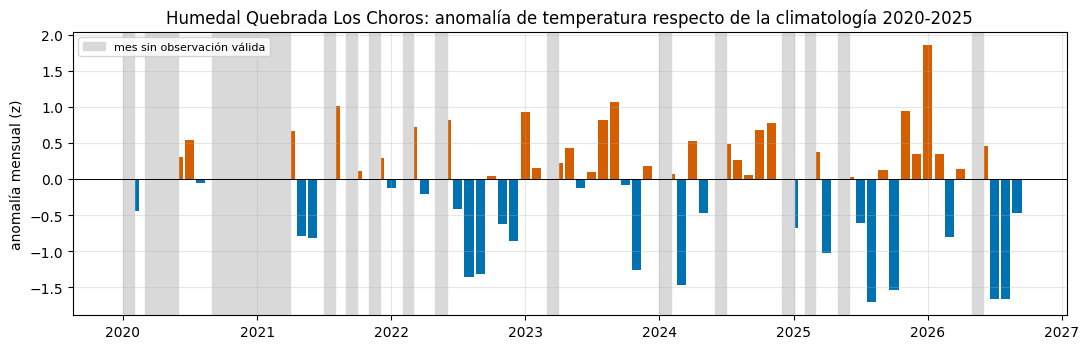

Humedal Quebrada Los Choros – anomalía media mensual reciente (z), NaN = sin observación válida:
fecha
2026-01-01    1.86
2026-02-01    0.34
2026-03-01   -0.81
2026-04-01    0.13
2026-05-01     NaN
2026-06-01    0.46
2026-07-01   -1.66
2026-08-01   -1.67
2026-09-01   -0.47
Freq: MS



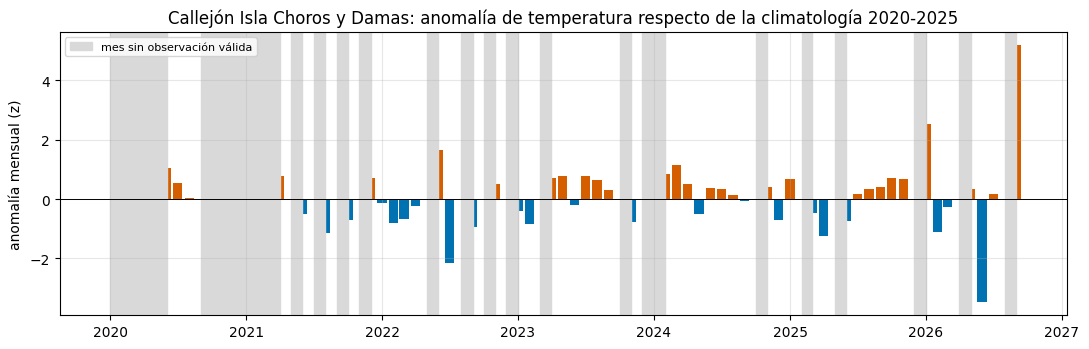

Callejón Isla Choros y Damas – anomalía media mensual reciente (z), NaN = sin observación válida:
fecha
2026-01-01    2.53
2026-02-01   -1.13
2026-03-01   -0.28
2026-04-01     NaN
2026-05-01    0.33
2026-06-01   -3.48
2026-07-01    0.17
2026-08-01     NaN
2026-09-01    5.20
Freq: MS



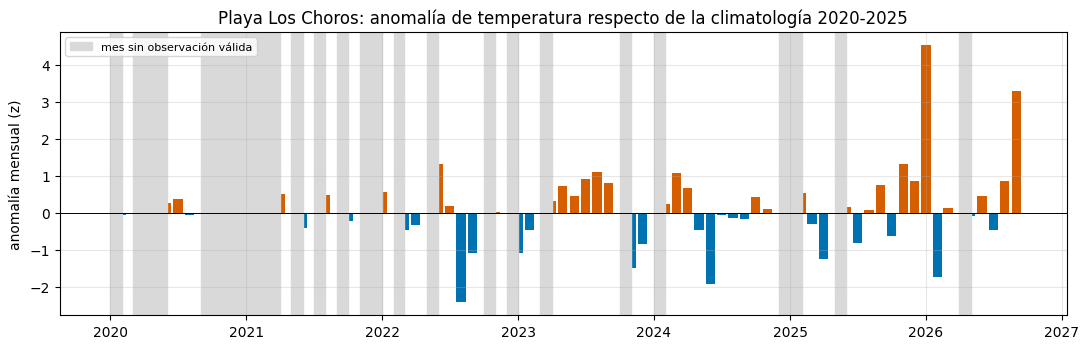

Playa Los Choros – anomalía media mensual reciente (z), NaN = sin observación válida:
fecha
2026-01-01    4.54
2026-02-01   -1.74
2026-03-01    0.12
2026-04-01     NaN
2026-05-01   -0.09
2026-06-01    0.44
2026-07-01   -0.46
2026-08-01    0.85
2026-09-01    3.28
Freq: MS



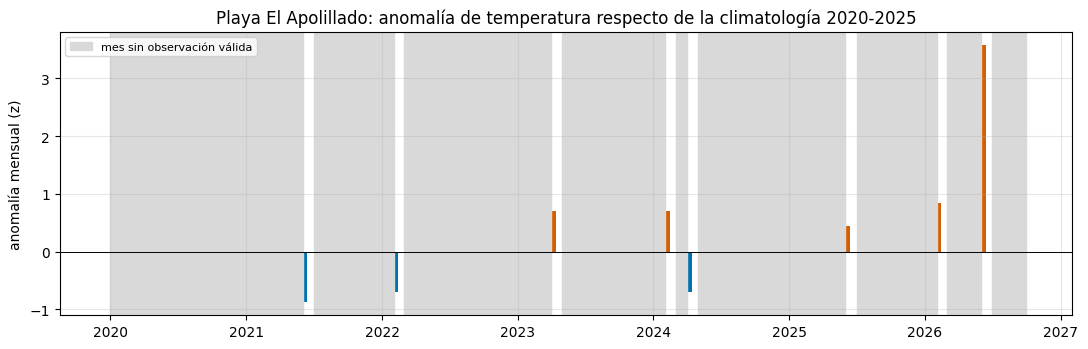

Playa El Apolillado – anomalía media mensual reciente (z), NaN = sin observación válida:
fecha
2026-01-01     NaN
2026-02-01    0.85
2026-03-01     NaN
2026-04-01     NaN
2026-05-01     NaN
2026-06-01    3.58
2026-07-01     NaN
2026-08-01     NaN
2026-09-01     NaN
Freq: MS



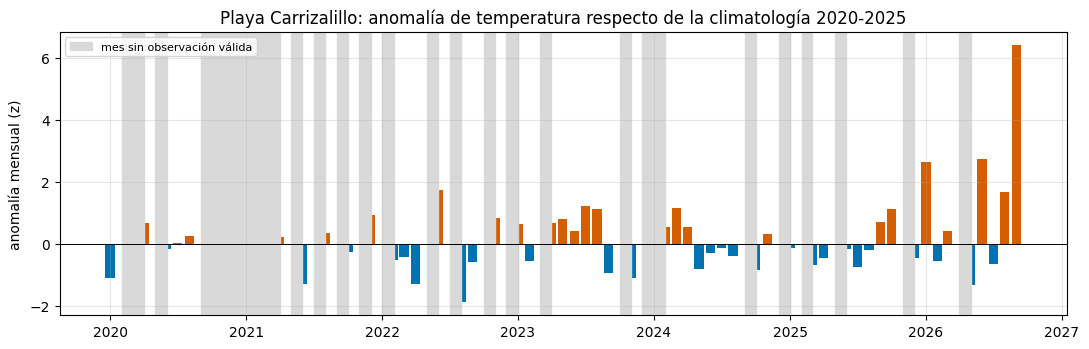

Playa Carrizalillo – anomalía media mensual reciente (z), NaN = sin observación válida:
fecha
2026-01-01    2.64
2026-02-01   -0.56
2026-03-01    0.40
2026-04-01     NaN
2026-05-01   -1.35
2026-06-01    2.74
2026-07-01   -0.66
2026-08-01    1.68
2026-09-01    6.41
Freq: MS



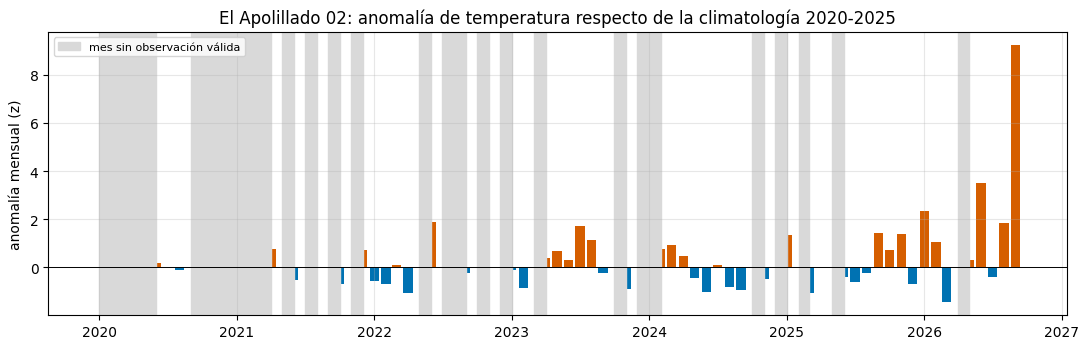

El Apolillado 02 – anomalía media mensual reciente (z), NaN = sin observación válida:
fecha
2026-01-01    2.34
2026-02-01    1.05
2026-03-01   -1.45
2026-04-01     NaN
2026-05-01    0.32
2026-06-01    3.51
2026-07-01   -0.39
2026-08-01    1.82
2026-09-01    9.24
Freq: MS



In [34]:
puntos = {
    "humedal_loschoros": "Humedal Quebrada Los Choros",
    "callejon": "Callejón Isla Choros y Damas",
    "playa_loschoros": "Playa Los Choros",
    "elapolillado": "Playa El Apolillado",
    "carrizalillo": "Playa Carrizalillo",
    "elapolillado02": "El Apolillado 02",
}
base_anios = (2020, 2025)

for id_punto, nombre_punto in puntos.items():
    st_punto = landsat[landsat["id"] == id_punto].set_index("fecha")["st_c"].astype(float)

    if st_punto.dropna().empty:
        print(f"{nombre_punto}: sin datos de temperatura válidos, se omite")
        continue

    z_st = anomalias_zscore(st_punto, referencia="mes", base=base_anios)
    z_mensual = z_st["2020":].resample("MS").mean()

    fig, eje = plt.subplots(figsize=(11, 3.6))
    eje.bar(z_mensual.index, z_mensual.fillna(0), width=25,
            color=np.where(z_mensual.fillna(0) >= 0, "#D55E00", "#0072B2"))
    for mes in z_mensual.index[z_mensual.isna()]:
        eje.axvspan(mes, mes + pd.offsets.MonthBegin(1), color="0.85", label="mes sin observación válida")
    manijas, nombres = eje.get_legend_handles_labels()
    eje.legend(dict(zip(nombres, manijas)).values(), dict(zip(nombres, manijas)).keys(),
               fontsize=8, loc="upper left")
    eje.axhline(0, color="k", linewidth=0.7)
    eje.set_ylabel("anomalía mensual (z)")
    eje.set_title(f"{nombre_punto}: anomalía de temperatura respecto de la climatología "
                  f"{base_anios[0]}-{base_anios[1]}")
    eje.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(f"{nombre_punto} – anomalía media mensual reciente (z), NaN = sin observación válida:")
    print(z_mensual["2026-01":].round(2).to_string())
    print()

## 8. Interpretación

La reflectancia roja (B04) aumenta con la turbidez del agua. Para comparar los sitios, se calcula la mediana mensual de B04 en cada localidad y se ordenan en una tabla con un mes por fila y un sitio por columna. La última columna indica el menor número de observaciones válidas entre los sitios en ese mes: si es bajo, la comparación de ese mes está poco respaldada. Igual que en el resto de la interpretación, las diferencias que aparezcan son una hipótesis. Para confirmarlas harían falta datos de terreno (turbidez o sólidos en suspensión, oleaje, surgencia), que aquí no tenemos. Además, el humedal se incluye solo como referencia, porque su píxel refleja principalmente suelo o vegetación y no agua.

In [35]:
sitios = ["humedal_loschoros", "callejon", "playa_loschoros",
          "elapolillado", "elapolillado02", "carrizalillo"]

datos_b04 = (tabla[tabla["id"].isin(sitios)]
             .dropna(subset=["b04"])
             .assign(mes=lambda d: d["fecha"].dt.to_period("M")))

mensual_b04 = datos_b04.pivot_table(index="mes", columns="id", values="b04", aggfunc="median")[sitios]
n_min = (datos_b04.pivot_table(index="mes", columns="id", values="b04", aggfunc="count")
         .reindex(columns=sitios).fillna(0).min(axis=1).astype(int).rename("n mínimo"))

pd.concat([mensual_b04.round(3), n_min], axis=1)

,humedal_loschoros,callejon,playa_loschoros,elapolillado,elapolillado02,carrizalillo,n mínimo
mes,,,,,,,
2020-01,0.228,0.035,0.012,0.049,0.026,0.065,3
2020-02,0.210,0.027,0.025,0.036,0.048,0.092,3
2020-03,0.213,0.003,0.006,0.055,0.009,0.007,3
2020-04,0.199,0.001,0.000,0.016,0.003,0.004,5
2020-05,0.200,0.005,0.005,0.025,0.007,0.001,3
...,...,...,...,...,...,...,...
2026-05,0.184,0.009,0.007,0.098,0.009,0.005,2
2026-06,0.181,0.004,0.010,0.059,0.009,0.009,3
2026-07,0.169,0.007,0.008,0.074,0.023,0.007,3


Clorofila entre localidades. El NDCI aumenta con la concentración de clorofila en el agua, así que sirve como indicador de fitoplancton. Para cada uno de los cinco sitios marinos se calcula la mediana mensual de NDCI y el número de observaciones válidas de cada mes. El resultado es una tabla con dos bloques: las medianas, para comparar los sitios mes a mes, y los conteos, para saber cuán respaldado está cada valor. El humedal queda fuera porque su píxel no corresponde a agua. Como no hay mediciones de clorofila en terreno, las diferencias entre sitios o entre meses se interpretan como hipótesis.

In [36]:
sitios_marinos = ["callejon", "playa_loschoros", "elapolillado", "elapolillado02", "carrizalillo"]

mensual_ndci = (tabla[tabla["id"].isin(sitios_marinos)]
                .assign(mes=lambda d: d["fecha"].dt.to_period("M"))
                .pivot_table(index="mes", columns="id", values="ndci", aggfunc=["median", "count"]))
mensual_ndci.round(3)

median                                                           \
id      callejon carrizalillo elapolillado elapolillado02 playa_loschoros   
mes                                                                         
2020-01    0.005        0.001       -0.035          0.015           0.017   
2020-02   -0.002        0.009       -0.038          0.012           0.010   
2020-03    0.000       -0.135       -0.066          0.005           0.003   
2020-04    0.000       -0.014       -0.045          0.000           0.000   
2020-05   -0.090       -0.082       -0.106         -0.092          -0.019   
...          ...          ...          ...            ...             ...   
2026-05   -0.134       -0.221       -0.098         -0.133          -0.239   
2026-06   -0.443       -0.333       -0.111         -0.308          -0.282   
2026-07   -0.160       -0.301       -0.095         -0.200          -0.250   
2026-08   -0.237       -0.170       -0.164         -0.110          -0.210   
2026-09   -0.133       -0.165       -0.145         -0.032          -0.127   

           count                                                           
id      callejon carrizalillo elapolillado elapolillado02 playa_loschoros  
mes                                                                        
2020-01        4            5            4              4               3  
2020-02        4            3            3              3               5  
2020-03        4            3            4              4               4  
2020-04        6            6            6              6               5  
2020-05        4            4            3              3               4  
...          ...          ...          ...            ...             ...  
2026-05        2            3            4              4               3  
2026-06        3            3            4              3               5  
2026-07        3            3            3              3               3  
2026-08        4            4            5              5               6  
2026-09        5            5            6              5               7  

[81 rows x 10 columns]

Vegetación en el humedal: El NDVI aumenta con la cantidad de vegetación verde y activa. Para el Humedal Quebrada Los Choros se calcula la mediana mensual de NDVI y el número de observaciones válidas de cada mes, y se muestran en una tabla con un mes por columna. Así se puede seguir cómo cambia el verdor del humedal a lo largo de los años. Sin datos de terreno sobre vegetación, lluvia o nivel de agua, los cambios que se observen se interpretan como hipótesis.

In [37]:
ndvi_humedal = tabla[tabla["id"] == "humedal_loschoros"].set_index("fecha")["ndvi"].dropna()
resumen_humedal = pd.DataFrame({
    "NDVI mediano": ndvi_humedal.resample("MS").median(),
    "n": ndvi_humedal.resample("MS").count(),
}).round(3)
resumen_humedal.index = resumen_humedal.index.strftime("%Y-%m")
resumen_humedal.T

fecha,2020-01,2020-02,2020-03,2020-04,2020-05,2020-06,2020-07,2020-08,2020-09,2020-10,...,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
NDVI mediano,0.043,0.05,0.057,0.058,0.065,0.085,0.13,0.106,0.094,0.074,...,0.073,0.059,0.061,0.066,0.06,0.084,0.08,0.086,0.122,0.158
n,4.000,5.00,4.000,5.000,5.000,6.000,8.00,7.000,3.000,5.000,...,7.000,4.000,10.000,7.000,5.00,3.000,4.00,3.000,3.000,7.000


El NDVI del humedal es muy bajo durante todo el periodo (entre 0.04 y 0.13). Eso indica vegetación escasa o suelo mayormente desnudo, no una cobertura vegetal densa. Aun así, se ve un ciclo estacional claro:

Verano (diciembre a febrero): valores mínimos, alrededor de 0.04–0.05.
Invierno (junio a agosto): el NDVI aumenta. En 2020 alcanzó su máximo en julio (0.13) y luego bajó gradualmente hacia la primavera.

Este patrón calza con un humedal de zona semiárida, donde la vegetación reverdece con las lluvias de invierno y se seca en verano.

El pico de invierno de 2021 fue más débil que el de 2020: el máximo fue 0.081 en julio. Una hipótesis es que ese invierno fue más seco, pero habría que confirmarlo con datos de precipitación o de caudal de la quebrada. Además, cada mes tiene solo entre 2 y 8 observaciones, así que los valores de meses con pocos datos (como noviembre de 2020 o septiembre de 2020) son menos confiables.

## Cierre

* Mira siempre **más de un estadístico** (media, mediana, percentiles) y **cuántos datos** hay detrás.
* Con fechas irregulares usa ventanas en **días** y exige un mínimo de observaciones.
* Una **tendencia** de un año mezcla estación y cambio: no la uses para concluir.
* Una **anomalía** necesita una climatología con varios años; con un año usa la referencia total y desconfía de los z extremos hasta mirar la imagen.
* Un **vacío** de datos no es un cero.

En el bloque 6 hacemos estos gráficos interactivos. En el 7 usamos la serie de TSM de décadas para detectar eventos extremos.